In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from RNN.RNN_Temperature import criterion

In [2]:
torch.cuda.is_available()

False

In [3]:
torch.cuda.device_count()

0

In [5]:
#will give error as there is no cuda available
# torch.cuda.get_device_name(0)

## Tensors
Tensor is basically high dimensional array<br>
0d tensor (scaler) eg. `a=5`<br>
1d tensor (vector) eg. `v=[1,2,3]`<br>
2d tensor (matrix) eg. `m=[[1,2,3], [4,5,6]]`<br>
Nd tensors (n-dimensional)<br>
- **3D Tensors**: Represent images (height, width, color channels).
- **4D Tensors**: Represent videos (frames, height, width, channels).
- **5D and Higher-Dimensional Tensors**: Used in advanced deep learning applications like reinforcement learning, 3D medical imaging, and volumetric data.<br>
<br>
Tensors behave similar to np arrays, and have the same operations

In [11]:
m = np.array([[1,1], [2,2]])
n = np.array([[2,2], [3,3]])
o = np.array([[2,2,4], [3,3,5]])

a = torch.tensor([[1, 1], [2, 2]])
b = torch.tensor([[2, 2], [3, 3]])
c = torch.tensor([[2, 2, 4], [3, 3, 5]])

In [12]:
m

array([[1, 1],
       [2, 2]])

In [10]:
a

tensor([[1, 1],
        [2, 2]])

In [13]:
(m+n)*5

array([[15, 15],
       [25, 25]])

In [14]:
(a+b)*5

tensor([[15, 15],
        [25, 25]])

In [30]:
o.sum()

19


tensor(19)

In [31]:
c.sum()

tensor(19)

In [17]:
# create tensor from specific numpy array
tensor = torch.from_numpy(m)
tensor

tensor([[1, 1],
        [2, 2]])

In [28]:
# ones and eros array and tensors also work the same
print(f'Numpy ones: {np.ones((2,4))}')
print(f'Torch ones: {torch.ones((2, 4))}')
torch.zeros((2,4))

Numpy ones: [[1. 1. 1. 1.]
 [1. 1. 1. 1.]]
Torch ones: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.]])

In [22]:
print(np.random.random((2,4)))
print('---------------------------------')
print(torch.rand((2,4)))

[[0.56110457 0.85495241 0.9214777  0.71684274]
 [0.15672664 0.44788867 0.73918016 0.94488978]]
---------------------------------
tensor([[0.4131, 0.1102, 0.4988, 0.4791],
        [0.3680, 0.4170, 0.8778, 0.0641]])


In [36]:
# shape and dtype for array
print('Array info')
print(m.shape)
print(m.dtype)
print(m.device)
print('---------------------------------')
print('Tensor info')
print(a.shape)
print(a.dtype)
print(a.device)

Array info
(2, 2)
int64
cpu
---------------------------------
Tensor info
torch.Size([2, 2])
torch.int64
cpu


The moment when we can see difference is when we want to put this onto the GPU. Numpy doesn't support GPU parallelism - it will give error.

In [37]:
m.to_device('cuda')

ValueError: Unsupported device: cuda. Only 'cpu' is accepted.

In [40]:
torch.cuda.is_available()

False

In [42]:
# This will work assuming GPU is available, in my case not as line above it specifies that it is not available.

# a.to('cuda')

# if we want to turn such tensor to numpy again
# a.cpu().numpy()

In [44]:
# good practice is setting the device as we don't know who will use our code
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# and then `.to(device)` whenever we have a model or a tensor, we just send it to the same device, which is necessary because if you have tensor on one device and model on another device, they cannot work together.

## Automatic Grad (Automatic differentiation)
What is actually happening when we're doing back propagation, optimization?

In [46]:
h = torch.tensor([2., 3.], requires_grad=True)
g = torch.tensor([6., 4.], requires_grad=True)

function = 3 * h**2 - g**2

This is how out function looks mathematically.

$$
f = 3h^3 - g^2
$$
Partial derivative of function with respect to h
$$
\frac{\partial f}{\partial h} = 9a^2
$$
Partial derivative of function with respect to g
$$
\frac{\partial f}{\partial g} = -2b
$$
<br>
This is what can be done but hand, but PyTorch can do it for us with automatic differentiation engine.

In [47]:
# value of function
function

tensor([-24.,  11.], grad_fn=<SubBackward0>)

In [49]:
# back propagate the gradient
function.backward(gradient=torch.tensor([1,1]))

# HOW DOES IT WORK
# we can provide a gradient, which is going to be a torch tensor. This tensor will say how important the individual values are (pass [1,1] to keep them equally)

In [54]:
print(f'Gradient with respect to h: {h.grad}')
print(f'Gradient with respect to g: {g.grad}')

Gradient with respect to h: tensor([12., 18.])
Gradient with respect to g: tensor([-12.,  -8.])


In [57]:
# we can check those gradients. h should be 9*h**2
print(9*h**2)
print(-2*g)

tensor([36., 81.], grad_fn=<MulBackward0>)
tensor([-12.,  -8.], grad_fn=<MulBackward0>)


## Loading datasets

In [60]:
import torch
import torch.nn as nn # will use it for model layers
import torch.nn.functional as F # functional is going to be used for activation functions eg. to break linearity
import torch.optim as optim # optimizers we will use
from torch.utils.data import DataLoader, TensorDataset

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [61]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [64]:
print(X_train_scaled.shape)
print(X_train_scaled.dtype)
X_train_scaled

(455, 30)
float64


array([[-1.44075296, -0.43531947, -1.36208497, ...,  0.9320124 ,
         2.09724217,  1.88645014],
       [ 1.97409619,  1.73302577,  2.09167167, ...,  2.6989469 ,
         1.89116053,  2.49783848],
       [-1.39998202, -1.24962228, -1.34520926, ..., -0.97023893,
         0.59760192,  0.0578942 ],
       ...,
       [ 0.04880192, -0.55500086, -0.06512547, ..., -1.23903365,
        -0.70863864, -1.27145475],
       [-0.03896885,  0.10207345, -0.03137406, ...,  1.05001236,
         0.43432185,  1.21336207],
       [-0.54860557,  0.31327591, -0.60350155, ..., -0.61102866,
        -0.3345212 , -0.84628745]], shape=(455, 30))

In [66]:
# target 0 or 1 depending on whether it's cancer or not
y_train

array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1,

#### Turning into tensors

In [67]:
X_train_scaled_tensor = torch.from_numpy(X_train_scaled).float()
X_test_scaled_tensor = torch.from_numpy(X_test_scaled).float()

# same thing done to y, PyTorch expects specific format so we unsqueeze to add additional dimension
y_train_tensor = torch.from_numpy(y_train).float().unsqueeze(1)
y_test_tensor = torch.from_numpy(y_test).float().unsqueeze(1)

In [68]:
train_dataset = TensorDataset(X_train_scaled_tensor, y_train_tensor)

In [69]:
X_train_scaled_tensor.shape

torch.Size([455, 30])

In [70]:
# create data loader to iterate over the data by using the train loader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

## Model

In [71]:
class BCNet(nn.Module):
    def __init__(self):
        super(BCNet, self).__init__()
        self.fc1 = nn.Linear(30, 64) # 30 features as input
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1) # 1 as output (0 or 1 - cancer or not cancer)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.sigmoid(self.fc3(x))

        # ReLU breaks linearity
        # Sigmoid classifiers

        return x

In [73]:
criterion = nn.BCELoss()
model = BCNet()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [74]:
epochs = 20

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()

        preds = model(x_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f'Epoch {epoch+1}: Loss was {running_loss/len(train_loader)}')


Epoch 1: Loss was 0.641313111782074
Epoch 2: Loss was 0.47348884542783104
Epoch 3: Loss was 0.30736325979232787
Epoch 4: Loss was 0.2074965015053749
Epoch 5: Loss was 0.14874562323093415
Epoch 6: Loss was 0.11226853815217813
Epoch 7: Loss was 0.09406678869078557
Epoch 8: Loss was 0.08643606913586457
Epoch 9: Loss was 0.07520606939991316
Epoch 10: Loss was 0.0796172758564353
Epoch 11: Loss was 0.06485619420806567
Epoch 12: Loss was 0.05664556167709331
Epoch 13: Loss was 0.055779878267397484
Epoch 14: Loss was 0.050318671576678756
Epoch 15: Loss was 0.046692316668728986
Epoch 16: Loss was 0.04469826541220148
Epoch 17: Loss was 0.04262809120118618
Epoch 18: Loss was 0.03970637045179804
Epoch 19: Loss was 0.04920037401219209
Epoch 20: Loss was 0.03564942851662636


In [75]:
with torch.no_grad():
    model.eval()
    preds = model(X_test_scaled_tensor)
    loss = criterion(preds, y_test_tensor).item()

    accuracy = ((preds>=0.5) == y_test_tensor).float().mean().item()

In [77]:
accuracy

0.9824561476707458

98% is a good performance, can check more with confusion matrix

In [80]:
from sklearn.metrics import confusion_matrix, classification_report

# preds come from the evaluation cell above (sigmoid outputs), threshold at 0.5
y_pred = (preds >= 0.5).int().numpy().ravel()
y_true = y_test_tensor.int().numpy().ravel()

cm = confusion_matrix(y_true, y_pred)
print(classification_report(y_true, y_pred, target_names=['malignant', 'benign']))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        43
      benign       0.99      0.99      0.99        71

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



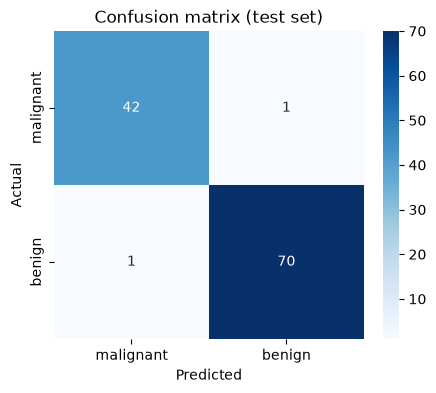

In [81]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['malignant', 'benign'],
            yticklabels=['malignant', 'benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix (test set)')
plt.show()

#### False positives and false negatives

Taking **malignant** as the positive class (the condition we want to detect):

- **False negatives (1) [top-right corner] :** a malignant tumour classified as benign. This is the more dangerous error, because a patient with cancer could miss treatment.
- **False positives (1) [bottom-left corner] :** a benign tumour classified as malignant. It is less harmful, but it still causes unnecessary stress and further tests.

With only one error of each type out of 114 test samples, the model is well balanced. In a medical setting, though, we would usually lower the decision threshold below 0.5 to reduce false negatives further, accepting some extra false positives.